In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [6]:
df = pd.read_csv("laptop_prices.csv")

In [8]:
print (df.shape)

(1275, 23)


In [10]:
display(df.head(8))

,Company,Product,TypeName,Inches,Ram,OS,Weight,Price_euros,Screen,ScreenW,...,RetinaDisplay,CPU_company,CPU_freq,CPU_model,PrimaryStorage,SecondaryStorage,PrimaryStorageType,SecondaryStorageType,GPU_company,GPU_model
0,Apple,MacBook Pro,Ultrabook,13.3,8,macOS,1.37,1339.69,Standard,2560,...,Yes,Intel,2.3,Core i5,128,0,SSD,No,Intel,Iris Plus Graphics 640
1,Apple,Macbook Air,Ultrabook,13.3,8,macOS,1.34,898.94,Standard,1440,...,No,Intel,1.8,Core i5,128,0,Flash Storage,No,Intel,HD Graphics 6000
2,HP,250 G6,Notebook,15.6,8,No OS,1.86,575.00,Full HD,1920,...,No,Intel,2.5,Core i5 7200U,256,0,SSD,No,Intel,HD Graphics 620
3,Apple,MacBook Pro,Ultrabook,15.4,16,macOS,1.83,2537.45,Standard,2880,...,Yes,Intel,2.7,Core i7,512,0,SSD,No,AMD,Radeon Pro 455
4,Apple,MacBook Pro,Ultrabook,13.3,8,macOS,1.37,1803.60,Standard,2560,...,Yes,Intel,3.1,Core i5,256,0,SSD,No,Intel,Iris Plus Graphics 650
5,Acer,Aspire 3,Notebook,15.6,4,Windows 10,2.10,400.00,Standard,1366,...,No,AMD,3.0,A9-Series 9420,500,0,HDD,No,AMD,Radeon R5
6,Apple,MacBook Pro,Ultrabook,15.4,16,Mac OS X,2.04,2139.97,Standard,2880,...,Yes,Intel,2.2,Core i7,256,0,Flash Storage,No,Intel,Iris Pro Graphics
7,Apple,Macbook Air,Ultrabook,13.3,8,macOS,1.34,1158.70,Standard,1440,...,No,Intel,1.8,Core i5,256,0,Flash Storage,No,Intel,HD Graphics 6000


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1275 entries, 0 to 1274
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Company               1275 non-null   object 
 1   Product               1275 non-null   object 
 2   TypeName              1275 non-null   object 
 3   Inches                1275 non-null   float64
 4   Ram                   1275 non-null   int64  
 5   OS                    1275 non-null   object 
 6   Weight                1275 non-null   float64
 7   Price_euros           1275 non-null   float64
 8   Screen                1275 non-null   object 
 9   ScreenW               1275 non-null   int64  
 10  ScreenH               1275 non-null   int64  
 11  Touchscreen           1275 non-null   object 
 12  IPSpanel              1275 non-null   object 
 13  RetinaDisplay         1275 non-null   object 
 14  CPU_company           1275 non-null   object 
 15  CPU_freq             

In [12]:
print("Missing values:\n", df.isnull().sum())

Missing values:
 Company                 0
Product                 0
TypeName                0
Inches                  0
Ram                     0
OS                      0
Weight                  0
Price_euros             0
Screen                  0
ScreenW                 0
ScreenH                 0
Touchscreen             0
IPSpanel                0
RetinaDisplay           0
CPU_company             0
CPU_freq                0
CPU_model               0
PrimaryStorage          0
SecondaryStorage        0
PrimaryStorageType      0
SecondaryStorageType    0
GPU_company             0
GPU_model               0
dtype: int64


In [4]:
df = df.drop_duplicates()

In [5]:
df = df.dropna()

In [13]:
plt.figure(figsize=(8, 4))
sns.histplot(df["Price"], bins=30, kde=True, color="steelblue")
plt.title("Distribution of Prices")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

KeyError: 'Price'

<Figure size 800x400 with 0 Axes>

In [14]:
# 1. Check and remove any duplicate rows
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates()

# 2. Feature Engineering: Combine Primary and Secondary storage (in GB)
df["TotalStorage"] = df["PrimaryStorage"] + df["SecondaryStorage"]

# 3. Check quick summary statistics of the numbers
display(df[["Inches", "Ram", "Weight", "Price_euros", "TotalStorage"]].describe())

Duplicates before: 0


,Inches,Ram,Weight,Price_euros,TotalStorage
count,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000
mean,15.022902,8.440784,2.040525,1134.969059,620.586667
std,1.429470,5.097809,0.669196,700.752504,482.064003
min,10.100000,2.000000,0.690000,174.000000,8.000000
25%,14.000000,4.000000,1.500000,609.000000,256.000000
50%,15.600000,8.000000,2.040000,989.000000,500.000000
75%,15.600000,8.000000,2.310000,1496.500000,1024.000000
max,18.400000,64.000000,4.700000,6099.000000,2560.000000


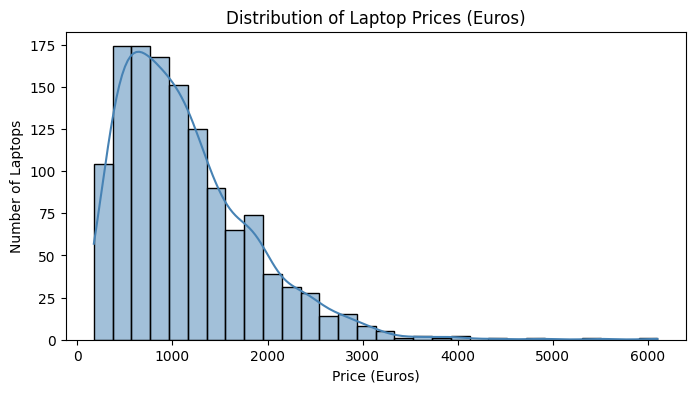

In [15]:
plt.figure(figsize=(8, 4))
sns.histplot(df["Price_euros"], bins=30, kde=True, color="steelblue")
plt.title("Distribution of Laptop Prices (Euros)")
plt.xlabel("Price (Euros)")
plt.ylabel("Number of Laptops")
plt.show()

/tmp/ipykernel_610/1397687687.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Ram", y="Price_euros", palette="Blues")


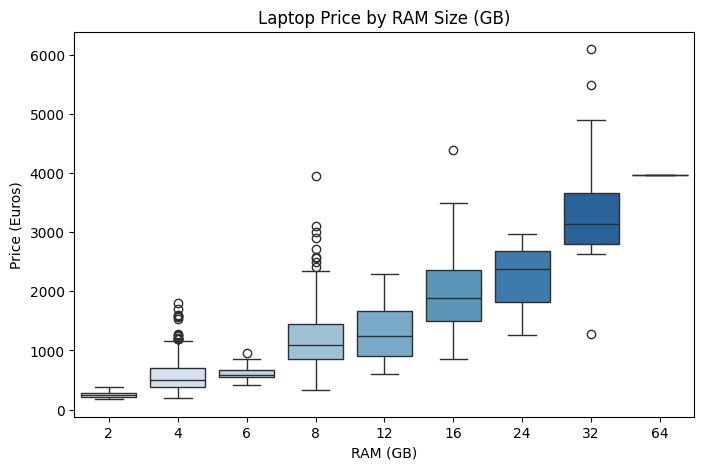

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Ram", y="Price_euros", palette="Blues")
plt.title("Laptop Price by RAM Size (GB)")
plt.xlabel("RAM (GB)")
plt.ylabel("Price (Euros)")
plt.show()

/tmp/ipykernel_610/3266301935.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_price_brand.index, y=avg_price_brand.values, palette="viridis")


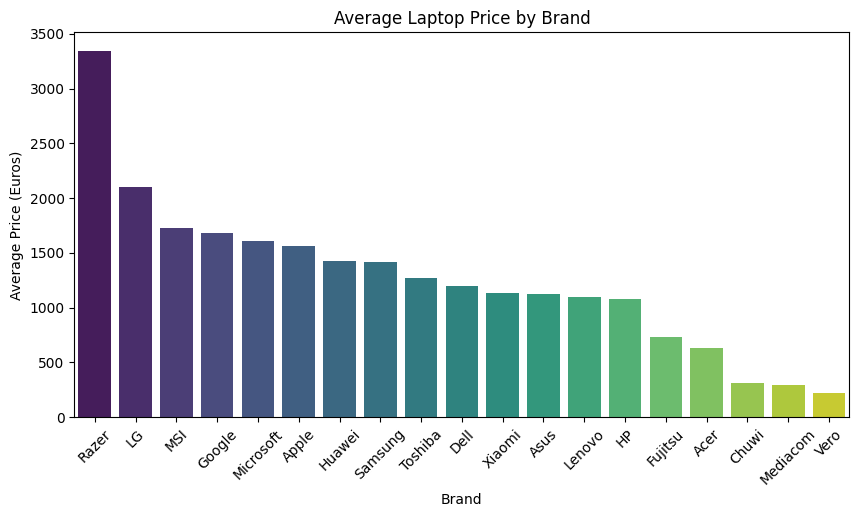

In [17]:
avg_price_brand = (
    df.groupby("Company")["Price_euros"].mean().sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=avg_price_brand.index, y=avg_price_brand.values, palette="viridis")
plt.title("Average Laptop Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price (Euros)")
plt.xticks(rotation=45)
plt.show()

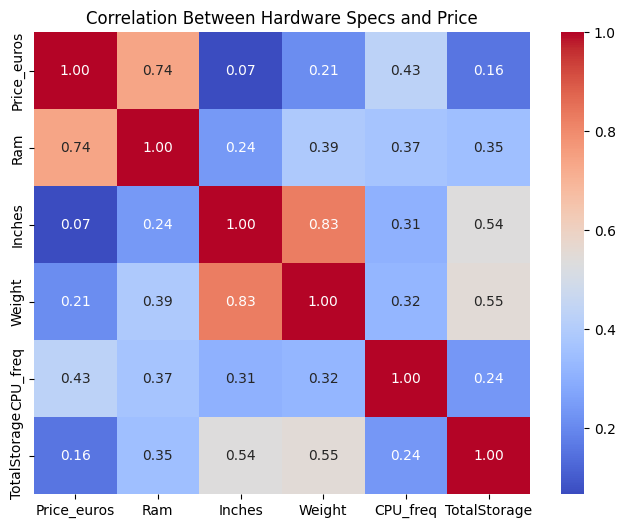

In [19]:
plt.figure(figsize=(8, 6))
numeric_cols = [
    "Price_euros",
    "Ram",
    "Inches",
    "Weight",
    "CPU_freq",
    "TotalStorage",
]
sns.heatmap(
    df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Correlation Between Hardware Specs and Price")
plt.show()

## Key Findings & Executive Summary
* **RAM is the Primary Price Driver:** Among all numeric hardware specifications, **RAM** shows the strongest positive correlation with laptop price (**r = 0.74**), followed by **CPU frequency (r = 0.43)**, while screen size (`Inches`, **r = 0.07**) has virtually no linear effect on price.
* **Market Price Distribution:** Laptop prices are heavily right-skewed, with most models concentrated in the **€400–€1,500** mid-range segment and a smaller premium tail extending above €3,000.
* **Brand Positioning:** Specialized gaming and ultrabook brands—led by **Razer** (~€3,350 avg) and **LG** (~€2,100 avg)—command the highest average prices, whereas budget brands (**Vero**, **Mediacom**, **Chuwi**) sit below €350.